# 2. Representación de soluciones y distancias

Antes de aplicar cualquier metaheurística hay que tomar dos decisiones. La primera es cómo se representa una solución del problema, es decir, qué estructura de datos la codifica y qué operadores pueden modificarla. La segunda es cómo se mide qué tan distintas son dos soluciones. De la representación dependen los vecindarios de los métodos de trayectoria, como el recocido simulado o la búsqueda en vecindarios grandes, y de la distancia dependen los mecanismos que miden y conservan la diversidad en los métodos poblacionales, como la búsqueda dispersa (*scatter search*) o los algoritmos meméticos.

Este capítulo trae dos ejemplos. En el primero se generan soluciones aleatorias con tres representaciones habituales en optimización combinatoria (vectores binarios, permutaciones y vectores de enteros), se calcula la matriz de distancias entre ellas con una medida acorde con cada representación y se proyectan en el plano para ver su dispersión. En el segundo se miden distancias entre registros de datos que mezclan variables numéricas, categóricas y binarias, un caso que aparece cuando las soluciones o los individuos se describen con atributos de distinto tipo.

## Representaciones y distancias en problemas combinatorios

En optimización combinatoria las soluciones suelen codificarse como vectores. Las tres familias que usa el ejemplo son estas:

- Vectores binarios, en los que cada posición es una decisión de sí o no. En el problema de la mochila, $x_i = 1$ indica que el objeto $i$ entra en la mochila; en el de cobertura de conjuntos, que el conjunto $i$ se elige.
- Permutaciones, en las que la solución es un orden de $n$ elementos y cada valor aparece una sola vez. Es la representación natural del problema del agente viajero (TSP) y de los problemas de asignación; hay $n!$ permutaciones posibles.
- Vectores de enteros, en los que cada posición toma uno de varios valores. En la coloración de grafos, por ejemplo, la posición $i$ guarda el color asignado al vértice $i$.

La medida de distancia debe ser coherente con la representación. El código usa las cuatro que ofrece `scipy.spatial.distance` y que se definen a continuación para dos vectores $x, y$ de dimensión $n$.

La distancia de Hamming de `scipy` es la fracción de posiciones en las que los vectores difieren,

$$d_H(x,y) = \frac{1}{n}\sum_{i=1}^{n} \mathbb{1}[x_i \neq y_i],$$

de modo que vale 0 si las soluciones son idénticas y 1 si no coinciden en ninguna posición. Multiplicada por $n$ da el número de posiciones distintas.

La distancia de Manhattan suma las diferencias absolutas,

$$d_M(x,y) = \sum_{i=1}^{n} |x_i - y_i|,$$

y en una permutación refleja cuánto cambiaron los valores de cada posición.

La distancia euclidiana es la longitud del segmento que une los dos vectores,

$$d_E(x,y) = \sqrt{\sum_{i=1}^{n} (x_i - y_i)^2},$$

y tiene sentido cuando los valores tienen significado cuantitativo, porque penaliza más las diferencias grandes.

La distancia de Jaccard, en la versión de `scipy`, solo mira las posiciones en las que al menos uno de los dos vectores es distinto de cero,

$$d_J(x,y) = \frac{\left|\{i : x_i \neq y_i,\ x_i \neq 0 \lor y_i \neq 0\}\right|}{\left|\{i : x_i \neq 0 \lor y_i \neq 0\}\right|}.$$

En un vector binario esto significa que dos soluciones no se parecen más por compartir objetos que ninguna de las dos eligió.

### Funciones

La primera celda carga las bibliotecas y fija el estilo de las figuras.

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from scipy.spatial.distance import hamming, euclidean, cityblock, jaccard
import seaborn as sns
from sklearn.manifold import MDS
from sklearn.decomposition import PCA

# Configuración para mostrar gráficos
plt.style.use('ggplot')
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 12

La función `generar_soluciones_ejemplo` produce `n_soluciones` vectores aleatorios de dimensión `dimension`: ceros y unos para el caso binario, permutaciones de $\{0, \dots, n-1\}$ y enteros entre 1 y 4 para el caso entero (cuatro colores, en el ejemplo de coloración).

In [2]:
# Función para generar soluciones aleatorias para problemas combinatorios
def generar_soluciones_ejemplo(tipo='binario', n_soluciones=10, dimension=8):
    """
    Genera soluciones aleatorias para diferentes tipos de problemas combinatorios.

    Args:
        tipo: Tipo de solución ('binario', 'permutacion', 'entero')
        n_soluciones: Número de soluciones a generar
        dimension: Dimensión de cada solución

    Returns:
        Lista de soluciones generadas
    """
    soluciones = []

    if tipo == 'binario':  # Para problemas como mochila, cobertura de conjuntos
        for _ in range(n_soluciones):
            soluciones.append(np.random.randint(0, 2, dimension))

    elif tipo == 'permutacion':  # Para problemas como TSP, asignación
        for _ in range(n_soluciones):
            soluciones.append(np.random.permutation(dimension))

    elif tipo == 'entero':  # Para problemas como coloración de grafos
        for _ in range(n_soluciones):
            soluciones.append(np.random.randint(1, 5, dimension))

    return np.array(soluciones)

La función `calcular_distancias` recorre los pares $(i, j)$ con $i < j$, calcula la distancia elegida y llena la matriz simétrica de distancias, cuya diagonal queda en cero.

In [3]:
# Función para calcular diferentes distancias entre soluciones
def calcular_distancias(soluciones, tipo_distancia='hamming'):
    """
    Calcula la matriz de distancias entre todas las soluciones.

    Args:
        soluciones: Array de soluciones
        tipo_distancia: Tipo de distancia a calcular

    Returns:
        Matriz de distancias
    """
    n = len(soluciones)
    matriz_distancias = np.zeros((n, n))

    for i in range(n):
        for j in range(i+1, n):
            if tipo_distancia == 'hamming':
                dist = hamming(soluciones[i], soluciones[j])
            elif tipo_distancia == 'euclidean':
                dist = euclidean(soluciones[i], soluciones[j])
            elif tipo_distancia == 'manhattan':
                dist = cityblock(soluciones[i], soluciones[j])
            elif tipo_distancia == 'jaccard':
                dist = jaccard(soluciones[i], soluciones[j])

            matriz_distancias[i, j] = dist
            matriz_distancias[j, i] = dist

    return matriz_distancias

Las tres funciones siguientes dibujan, respectivamente, las soluciones como una imagen (una fila por solución y una columna por posición), la matriz de distancias como mapa de calor y la proyección de las soluciones en el plano.

La proyección parte de la matriz de distancias. Con escalamiento multidimensional (*multidimensional scaling*, MDS), el método busca puntos en el plano cuyas distancias euclidianas se parezcan lo más posible a las de la matriz, de modo que dos soluciones cercanas en el gráfico son soluciones parecidas según la medida elegida. Con análisis de componentes principales (*principal component analysis*, PCA), cada solución se describe por su fila de la matriz, es decir, por el vector de sus distancias a todas las demás, y se proyecta sobre las dos direcciones de mayor varianza de esos vectores.

In [4]:
# Función para visualizar las soluciones
def visualizar_soluciones(soluciones, tipo='binario'):
    """
    Visualiza las soluciones generadas.

    Args:
        soluciones: Array de soluciones
        tipo: Tipo de solución
    """
    fig, ax = plt.subplots(figsize=(12, 6))

    if tipo == 'binario':
        cmap = ListedColormap(['white', 'blue'])
        ax.set_title('Representación de soluciones binarias')
    elif tipo in ['permutacion', 'entero']:
        cmap = plt.cm.viridis
        ax.set_title(f'Representación de soluciones tipo {tipo}')

    imagen = ax.imshow(soluciones, cmap=cmap, aspect='auto')
    ax.set_xlabel('Dimensión')
    ax.set_ylabel('Solución')
    plt.colorbar(imagen, ax=ax)
    plt.tight_layout()
    plt.show()

# Función para visualizar matriz de distancias
def visualizar_matriz_distancias(matriz_distancias, tipo_distancia):
    """
    Visualiza la matriz de distancias entre soluciones.

    Args:
        matriz_distancias: Matriz de distancias
        tipo_distancia: Tipo de distancia utilizada
    """
    plt.figure(figsize=(10, 8))
    sns.heatmap(matriz_distancias, annot=True, cmap='viridis', fmt='.2f')
    plt.title(f'Matriz de distancias ({tipo_distancia})')
    plt.tight_layout()
    plt.show()

# Función para visualizar soluciones en espacio bidimensional
def visualizar_espacio_soluciones(matriz_distancias, metodo='MDS'):
    """
    Proyecta las soluciones en un espacio bidimensional para visualización.

    Args:
        matriz_distancias: Matriz de distancias entre soluciones
        metodo: Método de reducción dimensional ('MDS' o 'PCA')
    """
    if metodo == 'MDS':
        embedding = MDS(n_components=2, dissimilarity='precomputed', random_state=42)
        pos = embedding.fit_transform(matriz_distancias)
    else:  # PCA
        embedding = PCA(n_components=2, random_state=42)
        pos = embedding.fit_transform(matriz_distancias)

    plt.figure(figsize=(10, 8))
    plt.scatter(pos[:, 0], pos[:, 1], s=100, c='blue', alpha=0.7)

    # Añadir etiquetas a los puntos
    for i in range(len(pos)):
        plt.annotate(str(i), (pos[i, 0], pos[i, 1]), fontsize=12)

    plt.title(f'Visualización de soluciones usando {metodo}')
    plt.xlabel('Dimensión 1')
    plt.ylabel('Dimensión 2')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

### Soluciones binarias

Se generan ocho soluciones binarias de dimensión 10, como si fueran ocho selecciones distintas de objetos en una mochila con diez candidatos. En la imagen, cada fila es una solución y cada celda azul es un objeto seleccionado.

[[1 1 0 0 1 1 1 1 1 0]
 [0 1 0 1 1 0 0 1 0 0]
 [0 1 0 0 1 0 0 0 1 0]
 [0 0 1 1 1 1 1 0 0 0]
 [1 1 1 1 1 1 0 1 1 0]
 [0 1 0 0 1 1 1 0 1 0]
 [0 1 1 0 1 1 1 1 0 0]
 [1 1 0 0 0 0 1 1 1 0]]


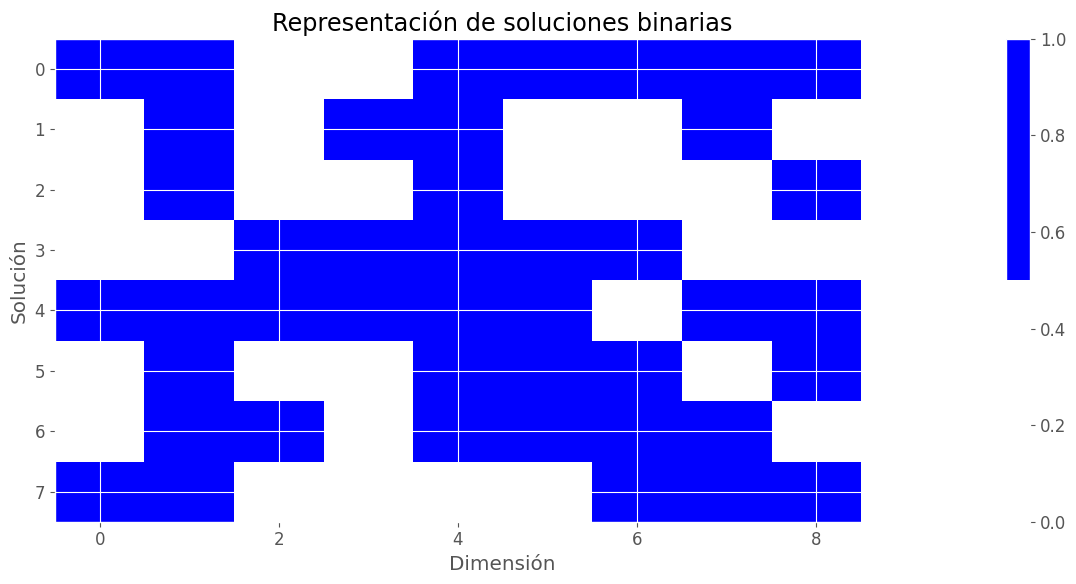

In [5]:
random.seed(1)
np.random.seed(1)

soluciones_binarias = generar_soluciones_ejemplo('binario', 8, 10)
print(soluciones_binarias)
visualizar_soluciones(soluciones_binarias, 'binario')

La matriz de Hamming muestra en cada celda la fracción de las diez decisiones en las que difieren dos soluciones. Es simétrica y tiene ceros en la diagonal; los valores más altos señalan los pares de soluciones más distintos.

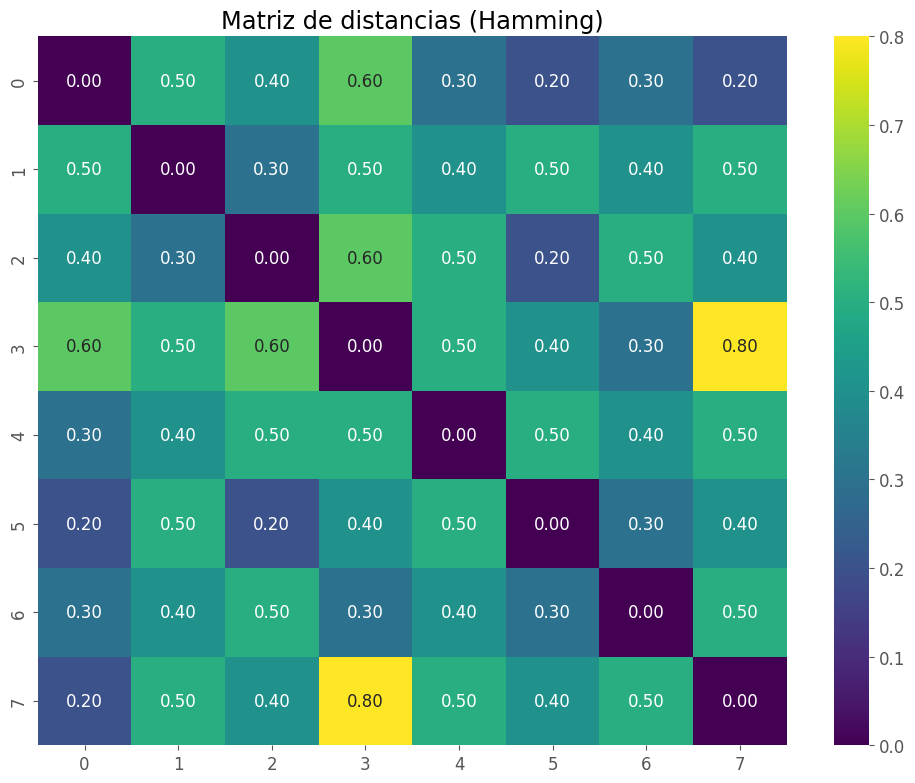

In [6]:
matriz_hamming = calcular_distancias(soluciones_binarias, 'hamming')
visualizar_matriz_distancias(matriz_hamming, 'Hamming')

Con la distancia de Jaccard, las posiciones en las que ninguna de las dos soluciones selecciona el objeto no cuentan como coincidencia. Por eso la matriz cambia respecto a la de Hamming, aunque las soluciones sean las mismas.

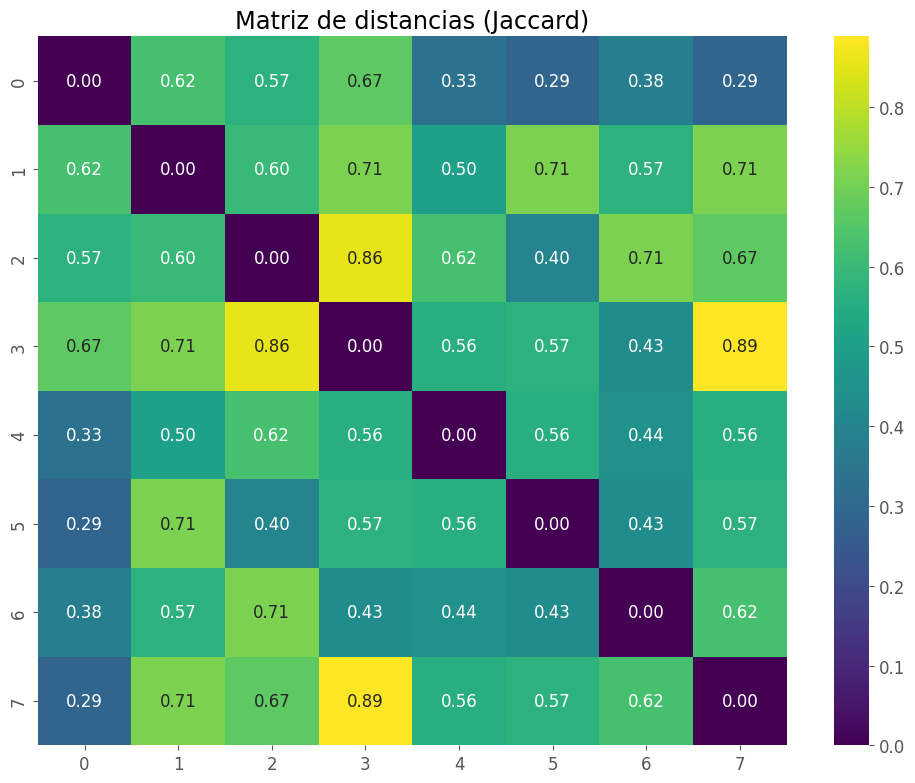

In [7]:
matriz_jaccard = calcular_distancias(soluciones_binarias, 'jaccard')
visualizar_matriz_distancias(matriz_jaccard, 'Jaccard')

La proyección con MDS de la matriz de Hamming permite ver de un vistazo qué soluciones forman grupos y cuáles quedan aisladas. Una población que se concentra en una zona del plano tiene poca diversidad.

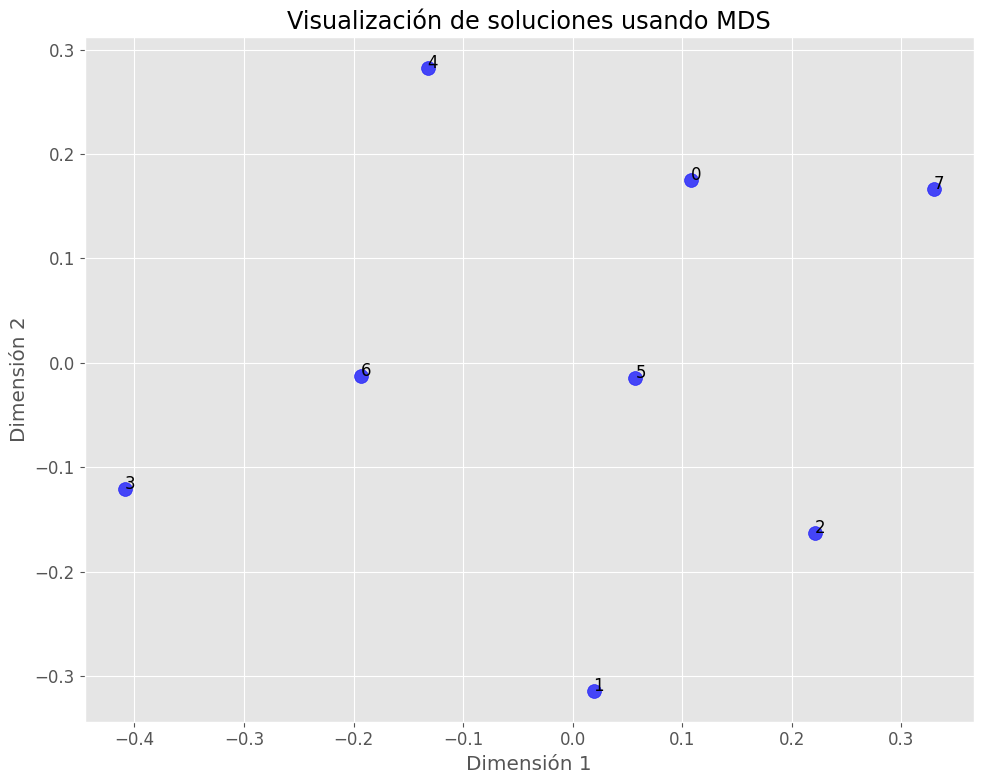

In [8]:
visualizar_espacio_soluciones(matriz_hamming)

La misma matriz proyectada con PCA da otra disposición de los puntos, porque PCA no intenta reproducir las distancias, sino resumir los vectores de distancias de cada solución.

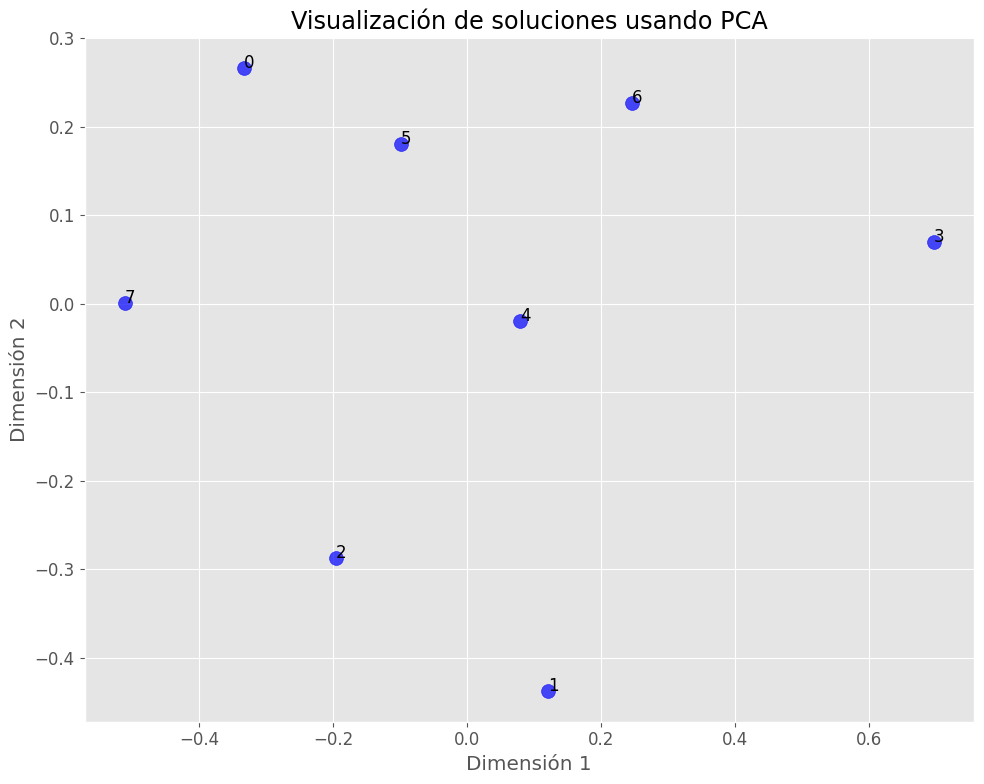

In [9]:
visualizar_espacio_soluciones(matriz_hamming, metodo='PCA')

### Permutaciones

Ahora cada solución es una permutación de los números $0, \dots, 9$, por ejemplo el orden en que un vehículo visita diez ciudades. En la imagen, el color de cada celda indica qué elemento ocupa esa posición.

[[4 1 5 0 7 2 3 6 9 8]
 [1 6 0 2 3 9 7 8 4 5]
 [4 9 5 0 8 1 2 6 7 3]
 [5 9 8 0 2 1 3 7 6 4]
 [5 3 8 6 7 0 1 9 4 2]
 [5 4 3 6 2 0 1 7 8 9]
 [1 6 5 4 2 7 8 0 3 9]
 [7 6 9 0 3 5 1 4 2 8]]


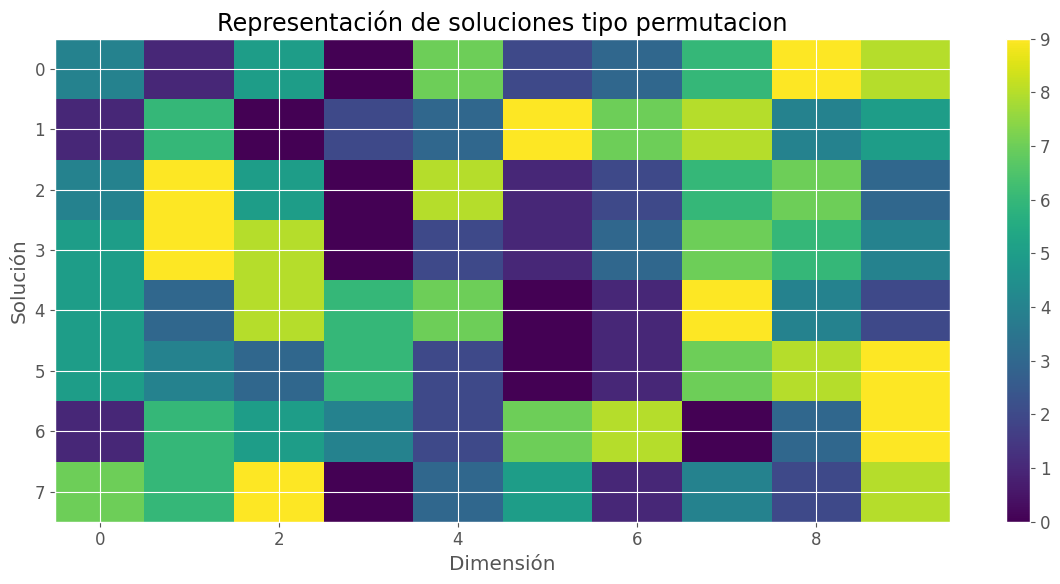

In [10]:
random.seed(2)
np.random.seed(2)

soluciones_perm = generar_soluciones_ejemplo('permutacion', 8, 10)
print(soluciones_perm)
visualizar_soluciones(soluciones_perm, 'permutacion')

Para permutaciones sirven tanto la distancia de Hamming, que cuenta las posiciones ocupadas por elementos distintos, como la de Manhattan, que además tiene en cuenta cuánto difieren los valores de cada posición. La matriz de Manhattan aparece primero y la de Hamming después, para comparar.

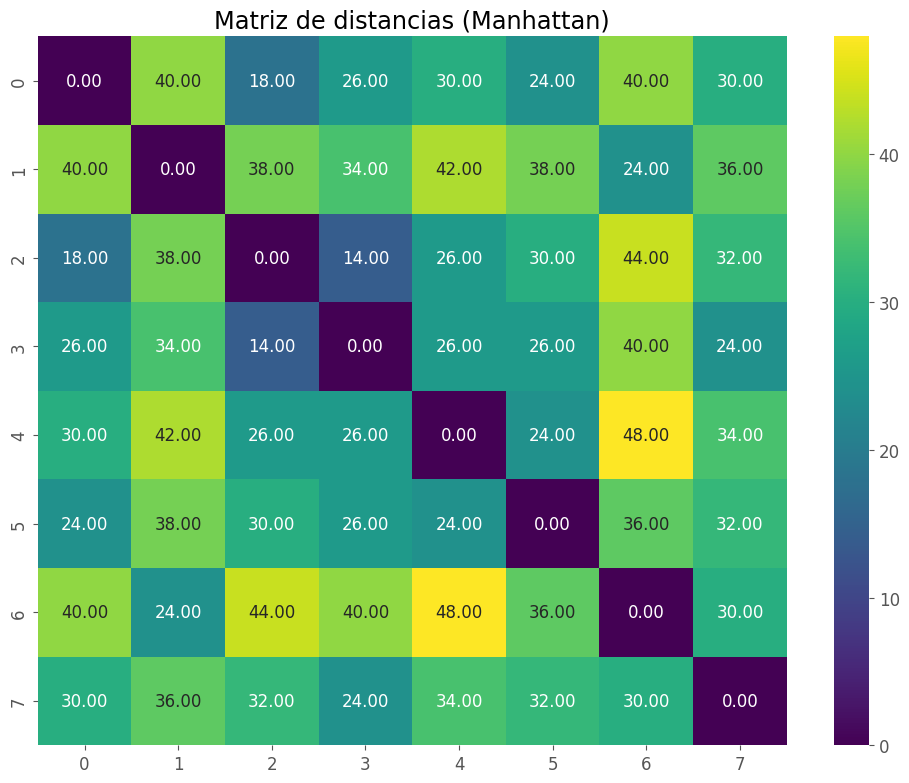

In [11]:
matriz_manhattan = calcular_distancias(soluciones_perm, 'manhattan')
visualizar_matriz_distancias(matriz_manhattan, 'Manhattan')

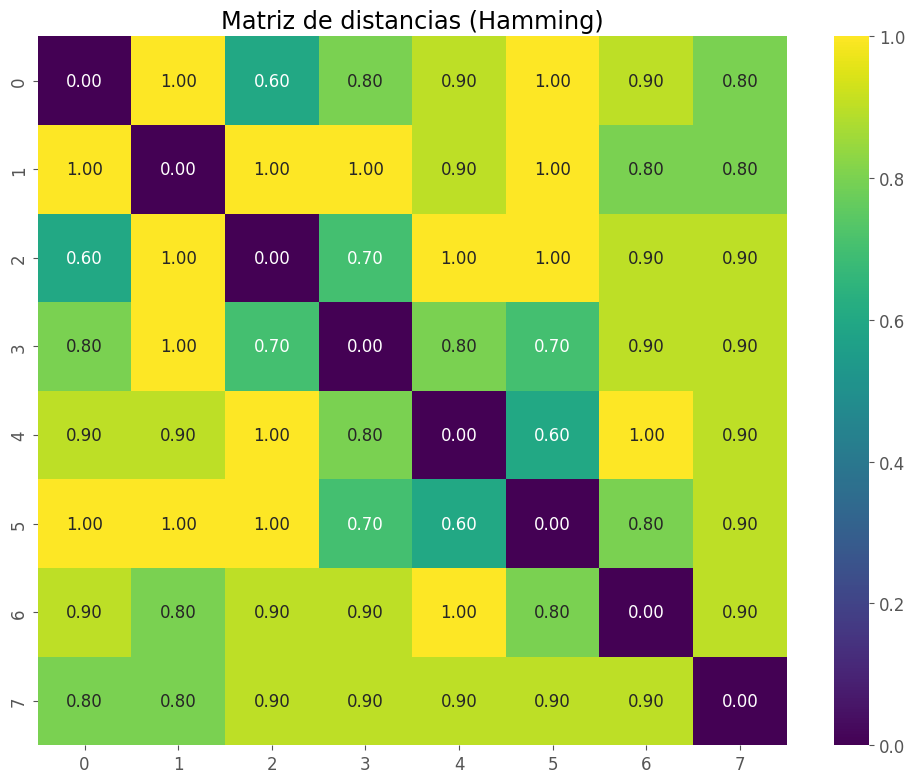

In [12]:
matriz_hamming_perm = calcular_distancias(soluciones_perm, 'hamming')
visualizar_matriz_distancias(matriz_hamming_perm, 'Hamming')

En permutaciones aleatorias pocas posiciones coinciden, de modo que la mayoría de los pares tiene distancias de Hamming altas y esa matriz discrimina poco entre ellos. La de Manhattan distingue, además, entre una permutación que cambió poco los valores de cada posición y otra que los cambió mucho, y por eso sus valores se reparten en un rango más amplio. La proyección con MDS se hace sobre la matriz de Manhattan.

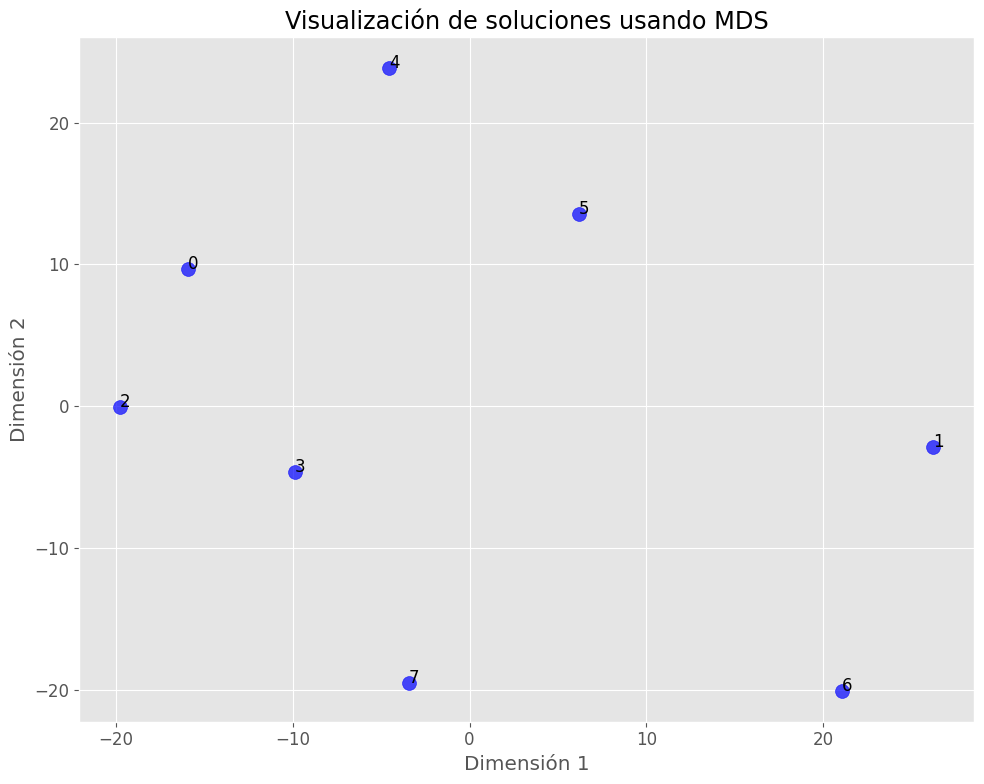

In [13]:
visualizar_espacio_soluciones(matriz_manhattan)

### Vectores de enteros

En el último caso, cada solución asigna a diez vértices un color entre 1 y 4.

[[3 1 2 4 1 1 1 2 2 4]
 [3 4 2 2 3 2 4 3 1 1]
 [1 2 4 3 1 3 2 3 3 3]
 [3 4 1 2 4 3 2 1 3 2]
 [2 3 1 4 3 4 1 4 2 4]
 [4 1 2 1 3 2 2 4 3 1]
 [1 4 3 1 1 2 3 1 4 2]
 [1 1 4 2 2 3 2 2 2 2]]


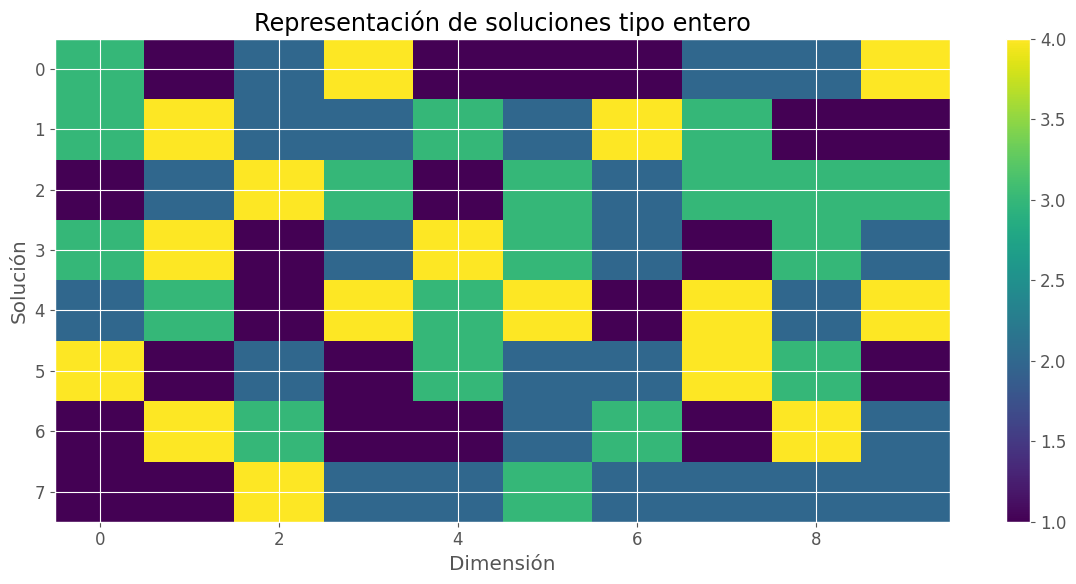

In [14]:
random.seed(3)
np.random.seed(3)

soluciones_enteros = generar_soluciones_ejemplo('entero', 8, 10)
print(soluciones_enteros)
visualizar_soluciones(soluciones_enteros, 'entero')

El código usa la distancia euclidiana. Al elevar al cuadrado las diferencias, dos soluciones que difieren en pocas posiciones pero con valores muy distantes pueden quedar más lejos que dos soluciones que difieren en muchas posiciones por una unidad. Esa lectura es adecuada cuando el valor entero mide una cantidad. Si el entero es solo una etiqueta, como un color, la distancia de Hamming es una alternativa que no supone ningún orden entre los valores.

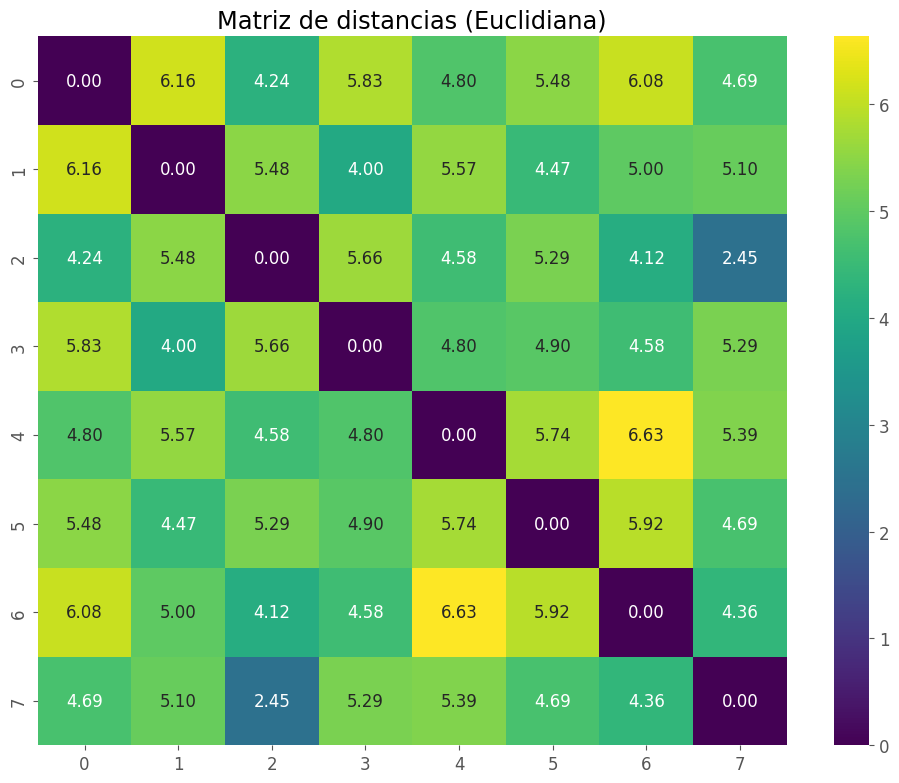

In [15]:
matriz_euclidean = calcular_distancias(soluciones_enteros, 'euclidean')
visualizar_matriz_distancias(matriz_euclidean, 'Euclidiana')

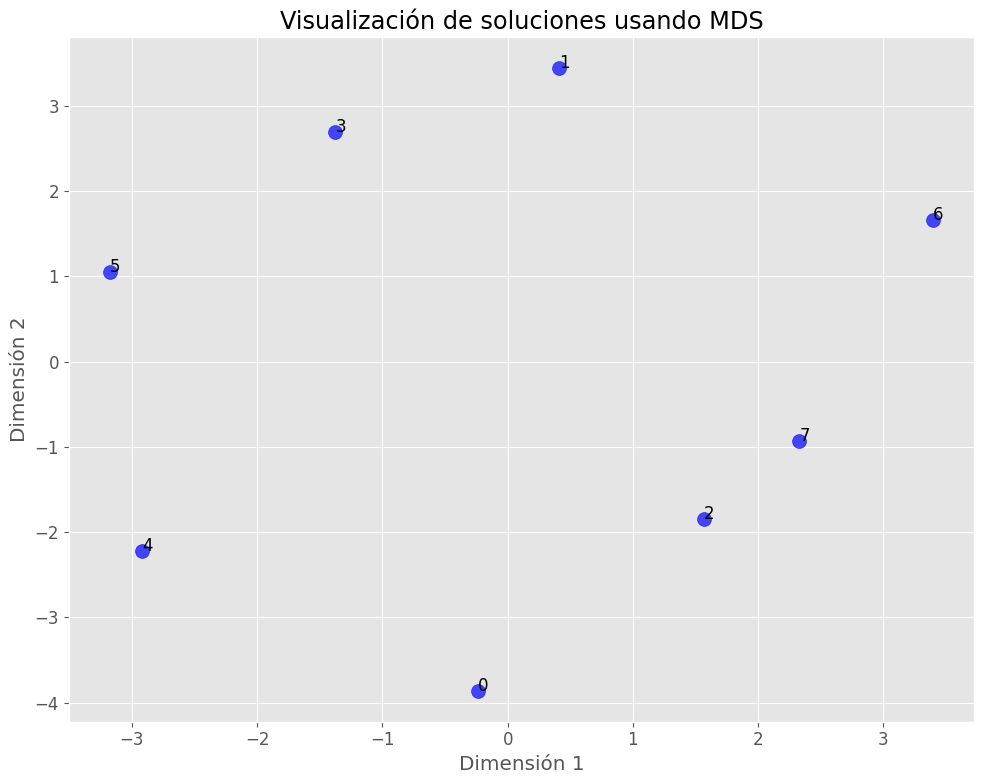

In [16]:
visualizar_espacio_soluciones(matriz_euclidean)

## Distancias con datos de tipos mixtos

Cuando los individuos se describen con atributos de distinto tipo, la distancia exige un preprocesamiento previo. El ejemplo usa un conjunto simulado de cuatro personas con dos variables numéricas (edad e ingreso), una categórica (género) y una binaria (si tiene casa propia).

In [17]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics.pairwise import euclidean_distances, cosine_distances
from scipy.spatial.distance import hamming, cityblock, canberra, jaccard
from itertools import combinations

# Simulated dataset with mixed data types
data = pd.DataFrame({
    'age': [25, 30, 45, 35],
    'income': [50000, 60000, 80000, 75000],
    'gender': ['male', 'female', 'female', 'male'],
    'owns_house': [1, 0, 1, 0]
})

print("Dataset original:")
print(data)

Dataset original:
   age  income  gender  owns_house
0   25   50000    male           1
1   30   60000  female           0
2   45   80000  female           1
3   35   75000    male           0


Sin preprocesamiento, el ingreso, que se mide en decenas de miles, dominaría cualquier distancia frente a la edad. Por eso las variables numéricas se llevan al intervalo $[0, 1]$ con la transformación mín-máx,

$$x' = \frac{x - \min(x)}{\max(x) - \min(x)},$$

la variable categórica se codifica con variables indicadoras (*one-hot*) y, como tiene solo dos categorías, se conserva una sola columna (`drop='if_binary'`). La variable binaria pasa sin cambios (`remainder='passthrough'`). Los imputadores rellenan valores faltantes con la media o con la moda; en este conjunto no hay faltantes.

In [18]:
# Define types of variables
numeric_features = ['age', 'income']
categorical_features = ['gender']
binary_features = ['owns_house']

# Preprocessing pipelines
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', MinMaxScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(drop='if_binary'))
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ],
    remainder='passthrough'  # keep binary columns
)

# Transform data
processed = preprocessor.fit_transform(data)
X = processed.astype(float)

print("Datos procesados (después de normalización y codificación):")
print(X)

Datos procesados (después de normalización y codificación):
[[0.         0.         1.         1.        ]
 [0.25       0.33333333 0.         0.        ]
 [1.         1.         0.         1.        ]
 [0.5        0.83333333 1.         0.        ]]


Sobre los datos procesados se calculan cinco matrices de distancias. Además de la euclidiana, la de Manhattan y la de Hamming, aparecen la distancia coseno,

$$d_C(x,y) = 1 - \frac{x \cdot y}{\lVert x \rVert \, \lVert y \rVert},$$

que compara la dirección de los vectores y no su magnitud, y la distancia de Canberra,

$$d_{Ca}(x,y) = \sum_{i=1}^{n} \frac{|x_i - y_i|}{|x_i| + |y_i|},$$

que pondera cada diferencia por el tamaño de los valores y, en `scipy`, toma como cero los términos en los que $x_i = y_i = 0$.

In [19]:
# Compute distance matrices
distances = {
    'Euclidiana': euclidean_distances(X),
    'Coseno': cosine_distances(X),
    'Manhattan': np.array([[cityblock(X[i], X[j]) for j in range(len(X))] for i in range(len(X))]),
    'Canberra': np.array([[canberra(X[i], X[j]) for j in range(len(X))] for i in range(len(X))]),
    'Hamming': np.array([[hamming(X[i], X[j]) for j in range(len(X))] for i in range(len(X))]),
}

# Mostrar las matrices de distancia
for name, dist_matrix in distances.items():
    print(f"Matriz de distancia {name}:")
    dist_df = pd.DataFrame(dist_matrix,
                          index=[f"Persona {i+1}" for i in range(len(X))],
                          columns=[f"Persona {i+1}" for i in range(len(X))])
    print(dist_df)
    print("\n")

Matriz de distancia Euclidiana:
           Persona 1  Persona 2  Persona 3  Persona 4
Persona 1   0.000000   1.474317   1.732051   1.394433
Persona 2   1.474317   0.000000   1.416667   1.145644
Persona 3   1.732051   1.416667   0.000000   1.509231
Persona 4   1.394433   1.145644   1.509231   0.000000


Matriz de distancia Coseno:
           Persona 1  Persona 2  Persona 3  Persona 4
Persona 1   0.000000   1.000000   0.591752   0.492907
Persona 2   1.000000   0.000000   0.191710   0.306767
Persona 3   0.591752   0.191710   0.000000   0.447948
Persona 4   0.492907   0.306767   0.447948   0.000000


Matriz de distancia Manhattan:
           Persona 1  Persona 2  Persona 3  Persona 4
Persona 1   0.000000   2.583333   3.000000   2.333333
Persona 2   2.583333   0.000000   2.416667   1.750000
Persona 3   3.000000   2.416667   0.000000   2.666667
Persona 4   2.333333   1.750000   2.666667   0.000000


Matriz de distancia Canberra:
           Persona 1  Persona 2  Persona 3  Persona 4
Persona 1

Los mapas de calor ponen las cinco matrices lado a lado. El orden de cercanía entre las personas no es el mismo en todas, porque cada medida da peso a aspectos distintos de los datos. La distancia de Hamming, aplicada a columnas continuas, trata como diferentes dos valores que no son exactamente iguales, sin importar cuánto se separan.

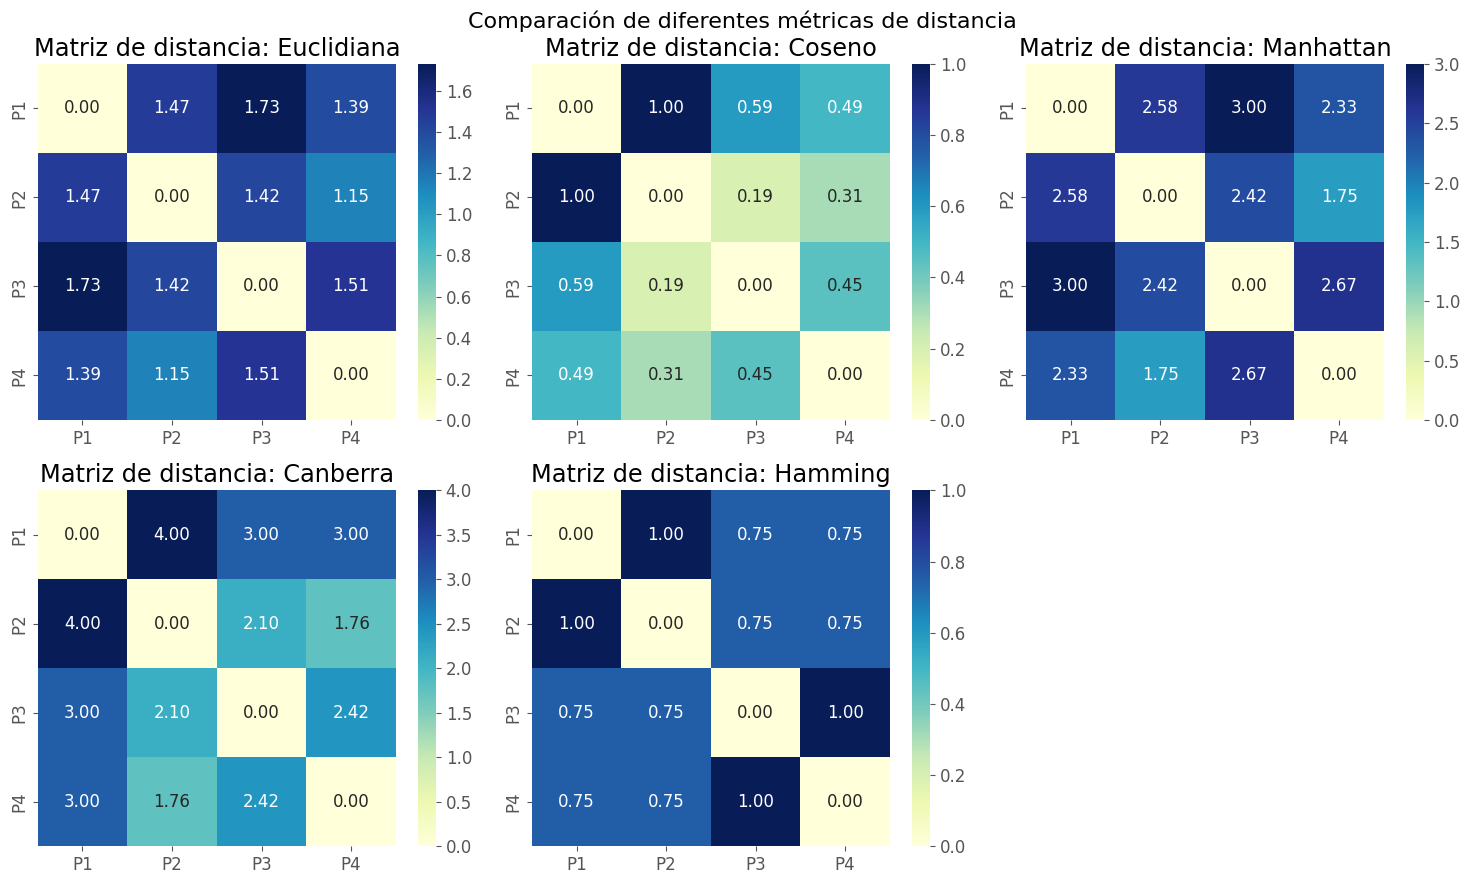

In [20]:
# Visualizar las matrices de distancia con heatmaps
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, (name, dist_matrix) in enumerate(distances.items()):
    if i < len(axes):
        sns.heatmap(dist_matrix, annot=True, fmt=".2f", cmap="YlGnBu", ax=axes[i])
        axes[i].set_title(f'Matriz de distancia: {name}')
        axes[i].set_xticklabels([f"P{i+1}" for i in range(len(X))])
        axes[i].set_yticklabels([f"P{i+1}" for i in range(len(X))])

# Eliminar el subplot extra si existe
if len(distances) < len(axes):
    fig.delaxes(axes[-1])

plt.tight_layout()
plt.suptitle("Comparación de diferentes métricas de distancia", fontsize=16)
plt.subplots_adjust(top=0.92)
plt.show()

La tabla y el gráfico de barras comparan, para cada par de personas, el valor de las cinco medidas. Las escalas no son comparables entre medidas (la coseno y la de Hamming están acotadas, la de Manhattan y la de Canberra crecen con el número de variables), así que lo que interesa es el orden de los pares dentro de cada medida.

Comparación de pares de personas según diferentes métricas:
                     Par  Euclidiana    Coseno  Manhattan  Canberra  Hamming
0  Persona 1 - Persona 2    1.474317  1.000000   2.583333  4.000000     1.00
1  Persona 1 - Persona 3    1.732051  0.591752   3.000000  3.000000     0.75
2  Persona 1 - Persona 4    1.394433  0.492907   2.333333  3.000000     0.75
3  Persona 2 - Persona 3    1.416667  0.191710   2.416667  2.100000     0.75
4  Persona 2 - Persona 4    1.145644  0.306767   1.750000  1.761905     0.75
5  Persona 3 - Persona 4    1.509231  0.447948   2.666667  2.424242     1.00


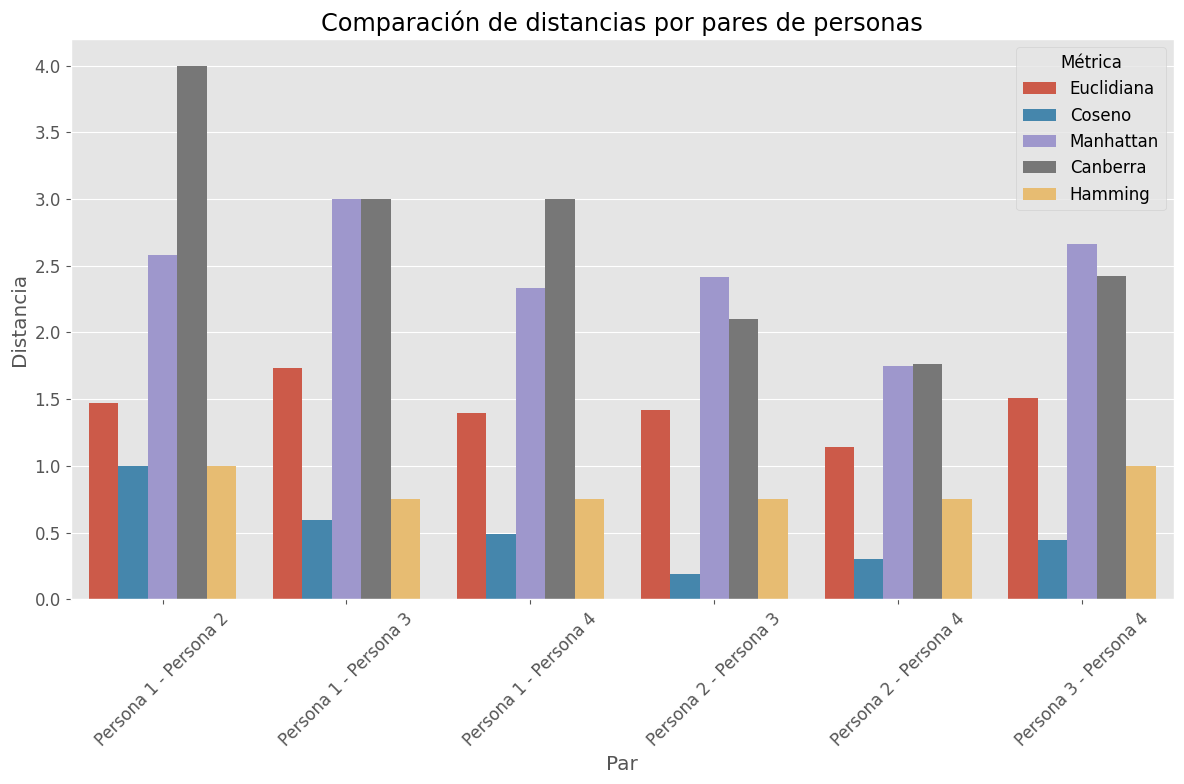

In [21]:
# Comparar pares de distancias
print("Comparación de pares de personas según diferentes métricas:")
personas = [f"Persona {i+1}" for i in range(len(X))]
pares = list(combinations(range(len(X)), 2))

comparison_data = []
for i, j in pares:
    row = {
        'Par': f"{personas[i]} - {personas[j]}",
    }
    for name, dist_matrix in distances.items():
        row[name] = dist_matrix[i, j]
    comparison_data.append(row)

comparison_df = pd.DataFrame(comparison_data)
print(comparison_df)

# Visualizar la comparación de pares
plt.figure(figsize=(12, 8))
comparison_melted = pd.melt(comparison_df, id_vars=['Par'], var_name='Métrica', value_name='Distancia')
sns.barplot(x='Par', y='Distancia', hue='Métrica', data=comparison_melted)
plt.title('Comparación de distancias por pares de personas')
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()